In [2]:
from langgraph.graph import START, END, StateGraph
from typing import TypedDict

In [4]:
class AgentState(TypedDict):
    question:str
    answer:str
    next_node:str
    db_files:list
    text_files:list
    

In [15]:
def Supervisor_Agent(state:AgentState):
    question=state['question']
    tool = select_tool(question)
    return {'next_node':tool}
def db_agent(state:AgentState):
    question=state['question']
    selected_db_files = select_db_files(question)
    answer=query_generator_tool(selected_db_files,files)
    return {'answer':answer}
def files_agent(state:AgentState):
    question=state['question']
    answer = rag_pipeline_tool(question)
    return {'answer':answer}

In [19]:
#tools
def select_tool(question):
    '''Code of Selected Tool'''
    tool = 'rag_pdf_tool' # 'query_generator_tool'
    return tool
def select_db_files(question):
    '''Code of Selected DB Files Tools which takes decision based of Files Description'''
    seleceted_db_files = ['employee_details.csv','emp1.csv','employee_db.csv']
    return selected_db_files
def query_generator_tool(files,question):
    '''Query Generator on Multiple files code'''
    answer='some random ans from query_generator'
    return answer
def rag_pipeline_tool(question):
    "code"
    answer = "Random Question From RAG Pipeline"
    return answer
def routing_function(state:AgentState):
    return state['Next Node']
    

In [21]:
graph = StateGraph(AgentState)
graph.add_node('Supervisor_Agent', Supervisor_Agent)
graph.add_node('DB_Agent', db_agent)
graph.add_node('Files_Agent', files_agent)
graph.add_edge(START, 'Supervisor_Agent')
graph.add_conditional_edges('Supervisor_Agent',routing_function,{'db': 'DB_Agent','files': 'Files_Agent','end': END})
graph.add_edge('DB_Agent', 'Supervisor_Agent')
graph.add_edge('Files_Agent', 'Supervisor_Agent')
app = graph.compile()
print(app)

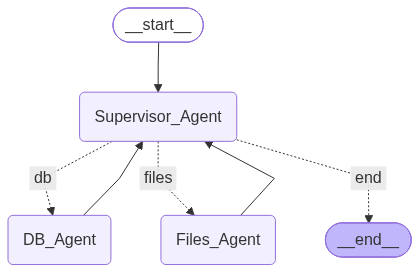

In [22]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))